In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import itertools

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [9]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)

In [10]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [11]:
df.columns

Index(['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume',
       'sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20', 'target_up_next', 'day', 'hour',
       'sum_of_scores', 'avg_of_scores', 'normalized_avg', 'max_of_scores',
       'min_of_scores', 'normalized_min', 'normalized_max',
       'avg_score_of_normalized_min', 'avg_score_of_normalized_max',
       'avg_score_of_normalized_avg'],
      dtype='object')

# LSTM

## Close price with avg min, and max score of all. 

In [12]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), :]          # full feature window
        dataX.append(a)
        dataY.append(dataset[i + look_back, target_col])
    return np.array(dataX), np.array(dataY)




16/16 [==============================] - 0s 1ms/step
Train Score: 4.45 RMSE
Test Score: 3.95 RMSE
16/16 [==============================] - 0s 2ms/step
Train Score: 4.90 RMSE
Test Score: 4.62 RMSE
16/16 [==============================] - 0s 1ms/step
Train Score: 4.91 RMSE
Test Score: 5.07 RMSE
16/16 [==============================] - 0s 2ms/step
Train Score: 5.23 RMSE
Test Score: 5.53 RMSE
16/16 [==============================] - 0s 2ms/step
Train Score: 5.47 RMSE
Test Score: 9.75 RMSE
16/16 [==============================] - 0s 1ms/step
Train Score: 4.38 RMSE
Test Score: 4.19 RMSE
16/16 [==============================] - 0s 2ms/step
Train Score: 4.32 RMSE
Test Score: 4.25 RMSE
16/16 [==============================] - 0s 1ms/step
Train Score: 4.84 RMSE
Test Score: 4.63 RMSE
16/16 [==============================] - 0s 2ms/step
Train Score: 4.79 RMSE
Test Score: 6.14 RMSE
16/16 [==============================] - 0s 1ms/step
Train Score: 5.30 RMSE
Test Score: 4.18 RMSE
10/10 [=============

9/9 [==============================] - 0s 3ms/step
Train Score: 4.45 RMSE
Test Score: 4.70 RMSE
9/9 [==============================] - 0s 3ms/step
Train Score: 4.84 RMSE
Test Score: 4.82 RMSE
9/9 [==============================] - 0s 3ms/step
Train Score: 4.50 RMSE
Test Score: 4.68 RMSE
9/9 [==============================] - 0s 2ms/step
Train Score: 4.96 RMSE
Test Score: 5.35 RMSE
9/9 [==============================] - 0s 3ms/step
Train Score: 4.09 RMSE
Test Score: 4.42 RMSE
9/9 [==============================] - 0s 2ms/step
Train Score: 4.68 RMSE
Test Score: 5.01 RMSE
15/15 [==============================] - 0s 3ms/step
Train Score: 5.61 RMSE
Test Score: 7.60 RMSE
15/15 [==============================] - 0s 3ms/step
Train Score: 4.90 RMSE
Test Score: 5.69 RMSE
15/15 [==============================] - 0s 3ms/step
Train Score: 5.14 RMSE
Test Score: 5.99 RMSE
15/15 [==============================] - 0s 3ms/step
Train Score: 5.53 RMSE
Test Score: 12.45 RMSE
15/15 [========================

/tmp/ipykernel_2696217/4087280326.py:172: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(12,6))


14/14 [==============================] - 0s 4ms/step
Train Score: 4.29 RMSE
Test Score: 8.46 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.43 RMSE
Test Score: 6.01 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.85 RMSE
Test Score: 9.77 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.84 RMSE
Test Score: 8.52 RMSE
14/14 [==============================] - 0s 5ms/step
Train Score: 4.91 RMSE
Test Score: 11.30 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.96 RMSE
Test Score: 20.94 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.90 RMSE
Test Score: 10.29 RMSE
14/14 [==============================] - 0s 5ms/step
Train Score: 4.70 RMSE
Test Score: 11.10 RMSE
14/14 [==============================] - 0s 4ms/step
Train Score: 4.45 RMSE
Test Score: 7.59 RMSE
7/7 [==============================] - 0s 5ms/step
Train Score: 3.81 RMSE
Test Score: 4.88 RMSE
7/7 [=============

6/6 [==============================] - 0s 6ms/step
Train Score: 4.29 RMSE
Test Score: 5.72 RMSE
6/6 [==============================] - 0s 6ms/step
Train Score: 4.46 RMSE
Test Score: 6.01 RMSE
6/6 [==============================] - 0s 6ms/step
Train Score: 4.09 RMSE
Test Score: 5.72 RMSE
6/6 [==============================] - 0s 6ms/step
Train Score: 4.61 RMSE
Test Score: 6.40 RMSE
6/6 [==============================] - 0s 6ms/step
Train Score: 4.00 RMSE
Test Score: 5.33 RMSE
12/12 [==============================] - 0s 6ms/step
Train Score: 4.43 RMSE
Test Score: 7.90 RMSE
12/12 [==============================] - 0s 6ms/step
Train Score: 4.74 RMSE
Test Score: 19.92 RMSE
12/12 [==============================] - 0s 6ms/step
Train Score: 4.22 RMSE
Test Score: 9.48 RMSE
12/12 [==============================] - 0s 6ms/step
Train Score: 4.80 RMSE
Test Score: 11.78 RMSE
12/12 [==============================] - 0s 6ms/step
Train Score: 4.92 RMSE
Test Score: 19.09 RMSE
12/12 [====================

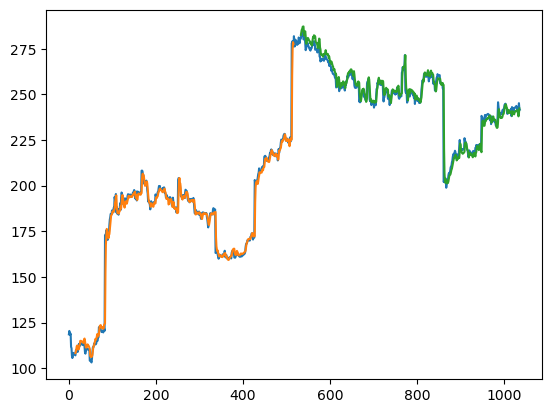

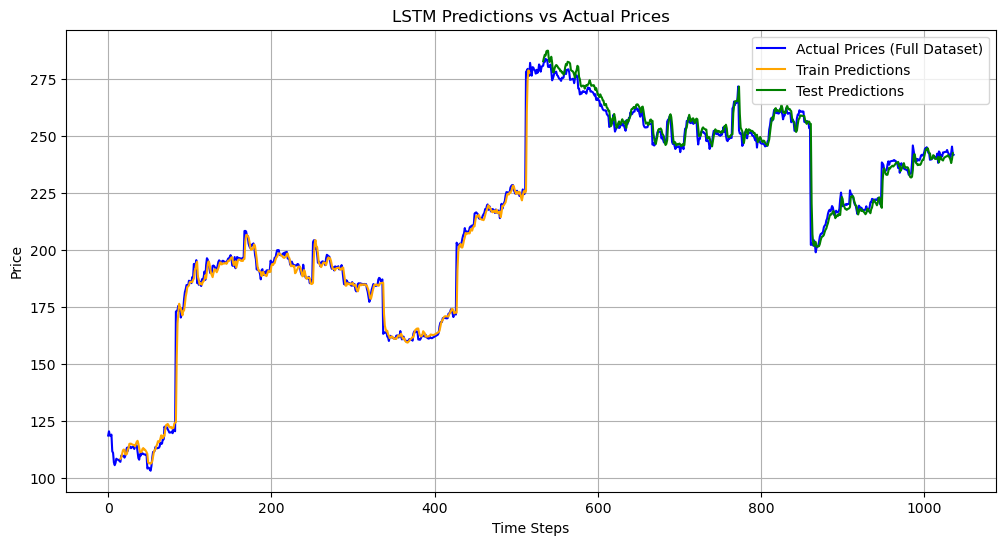

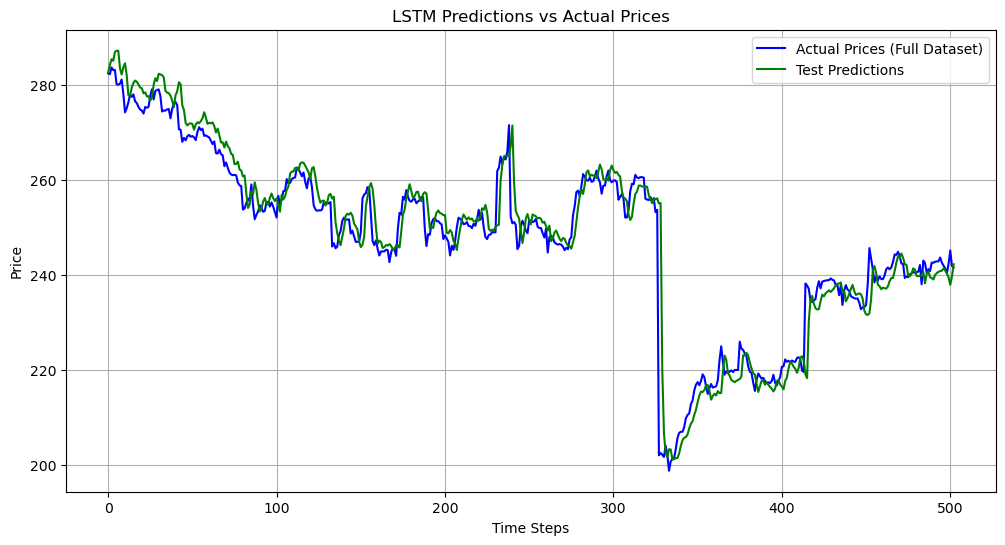

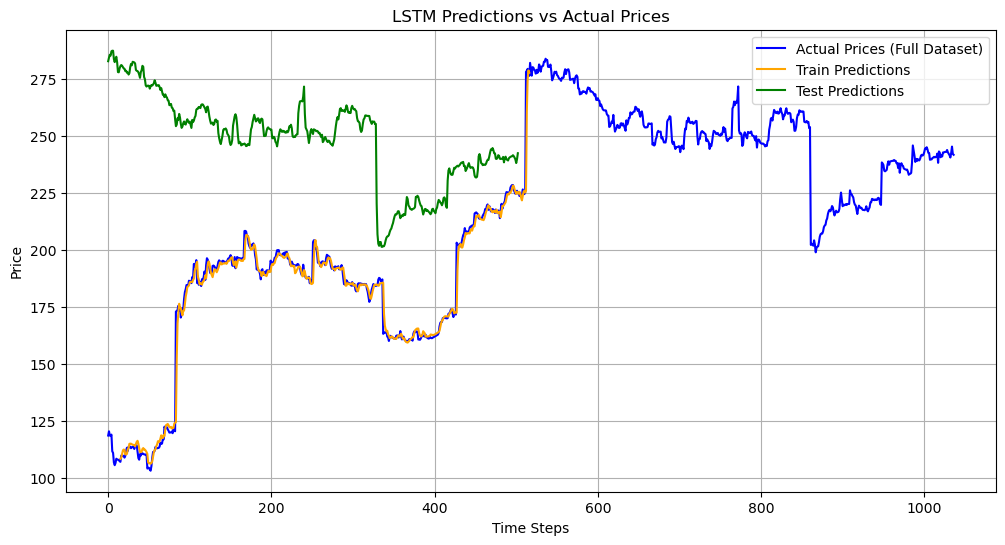

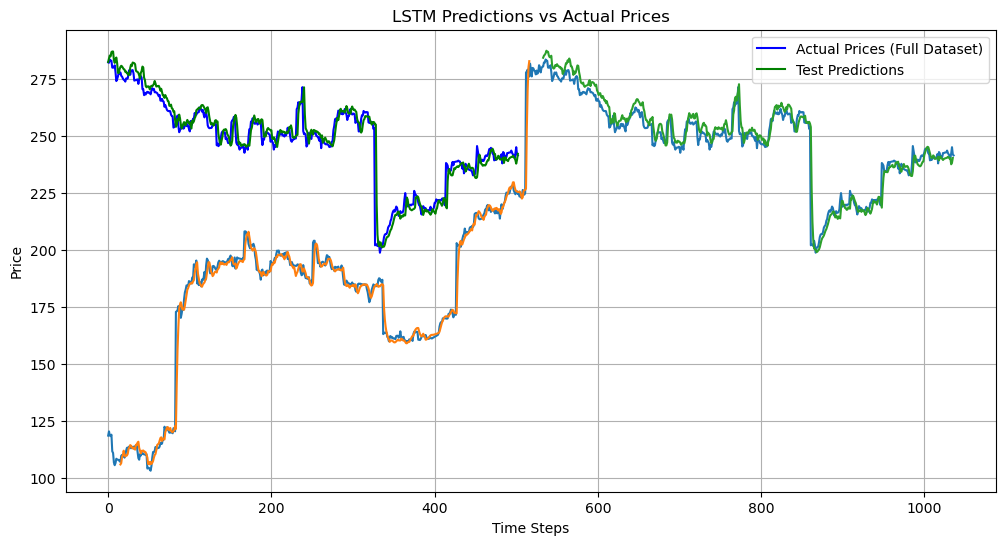

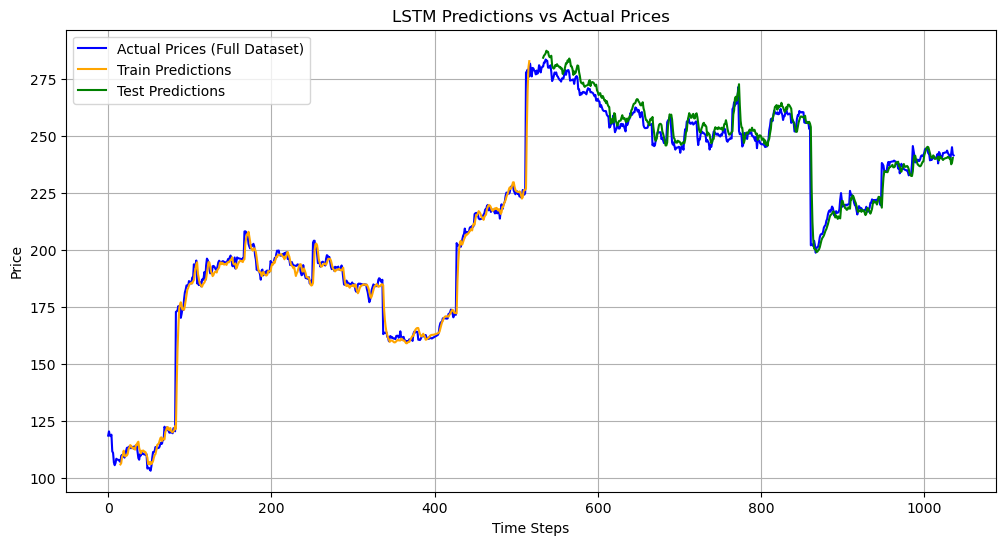

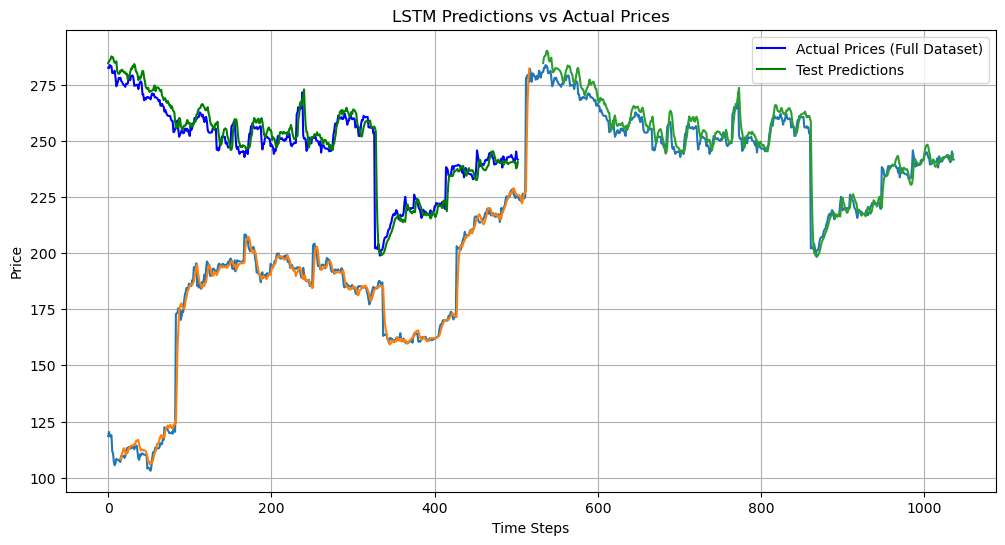

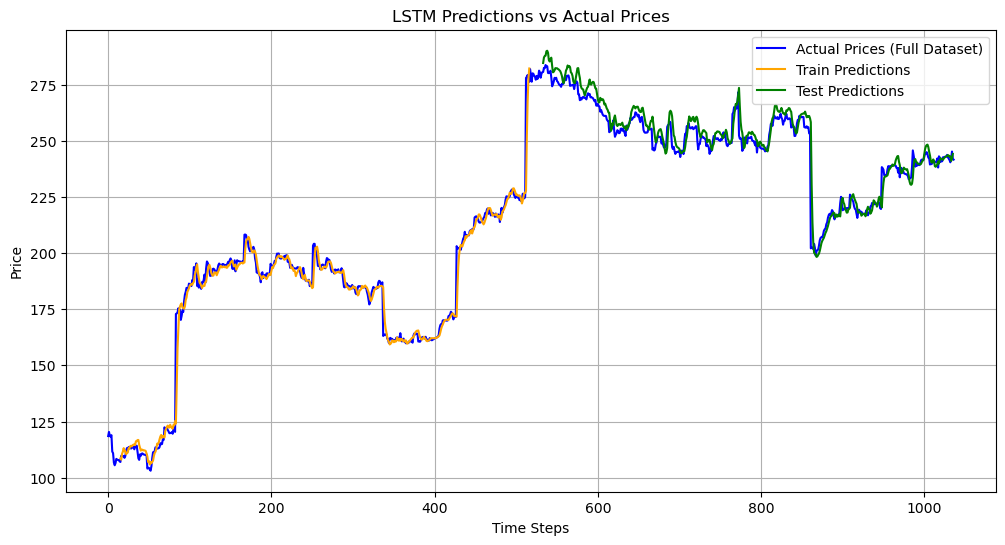

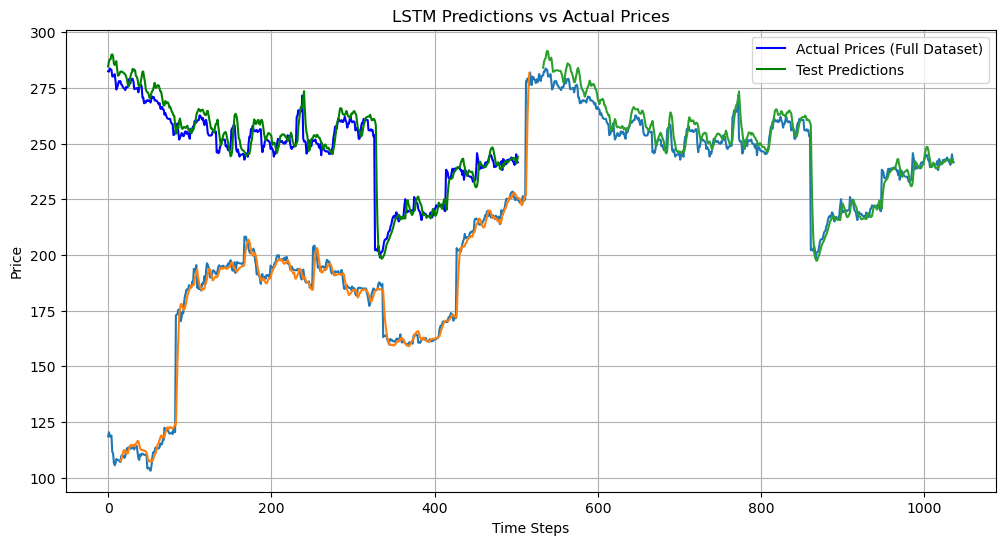

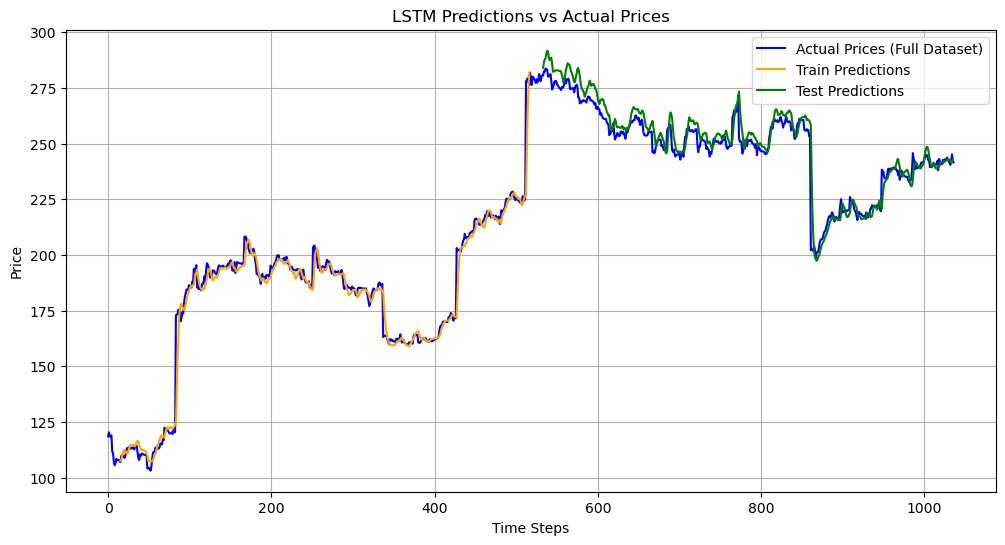

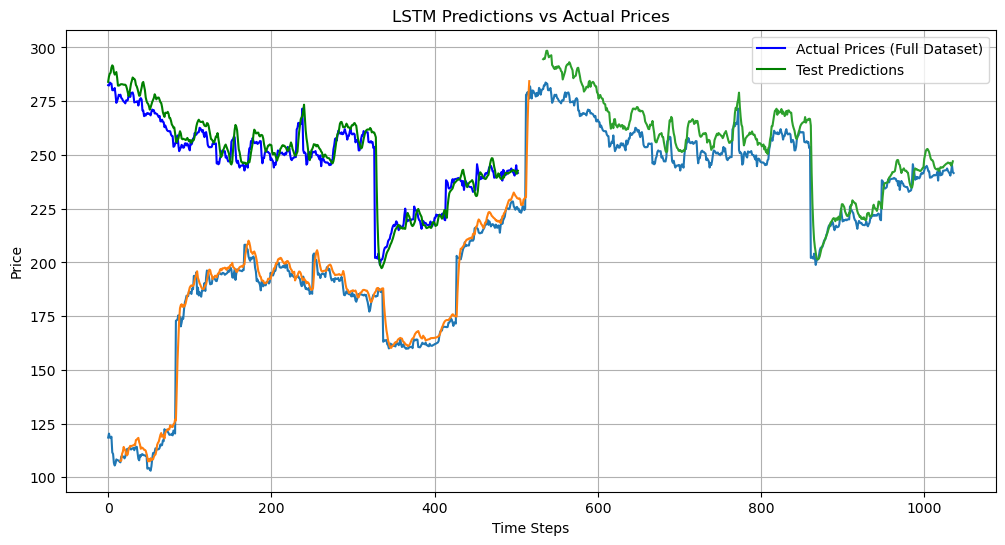

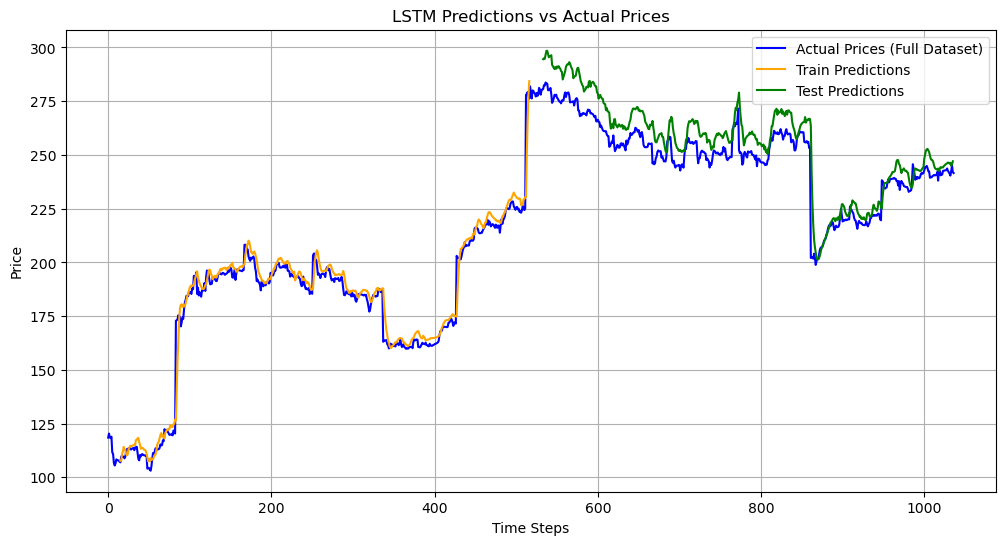

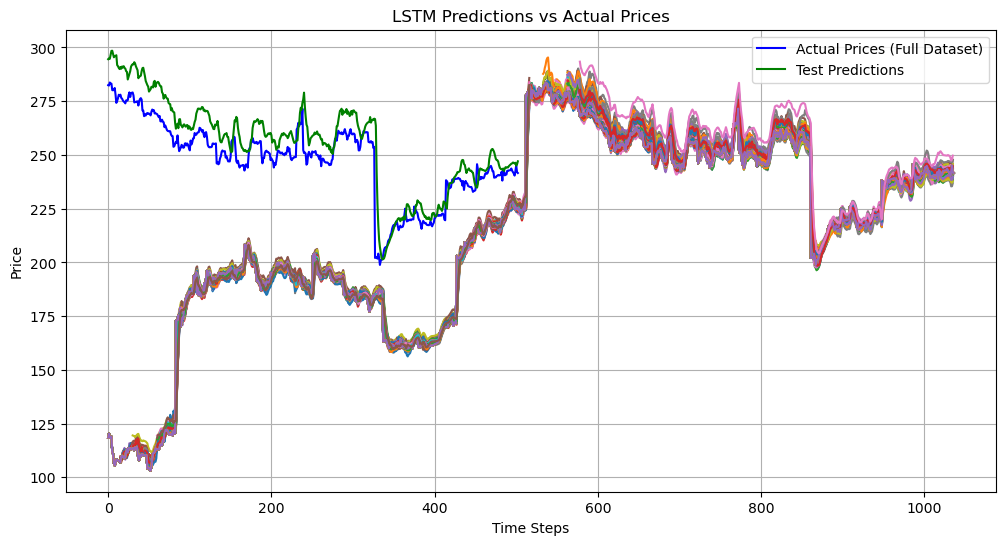

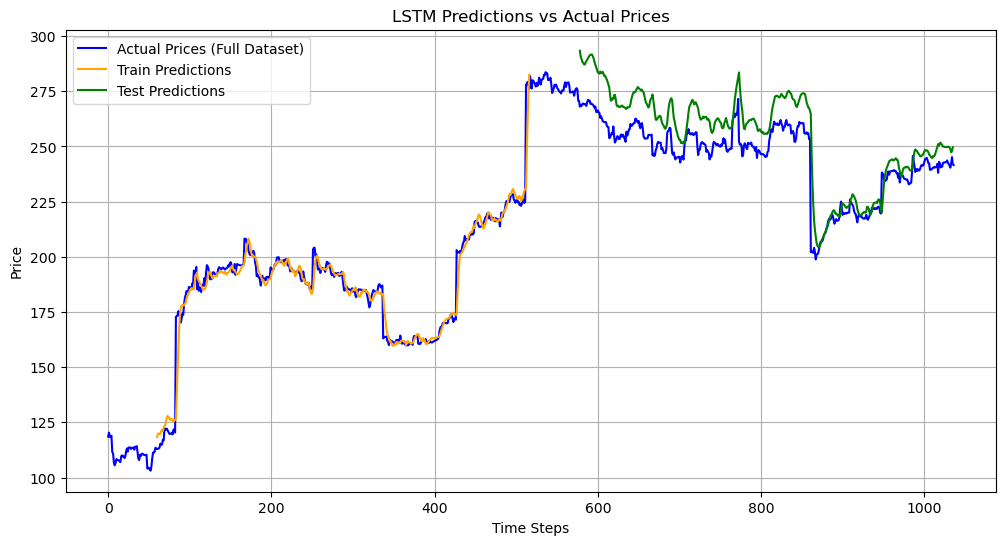

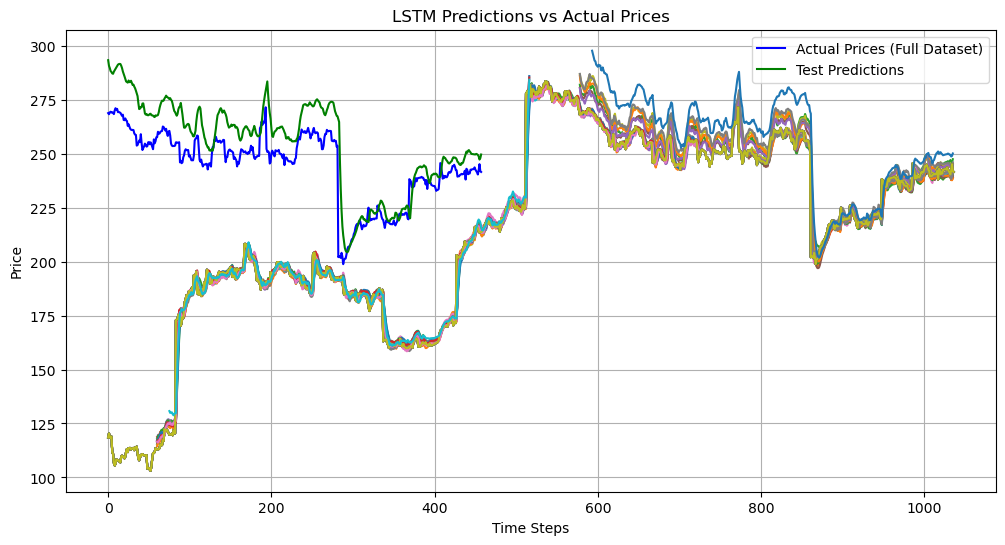

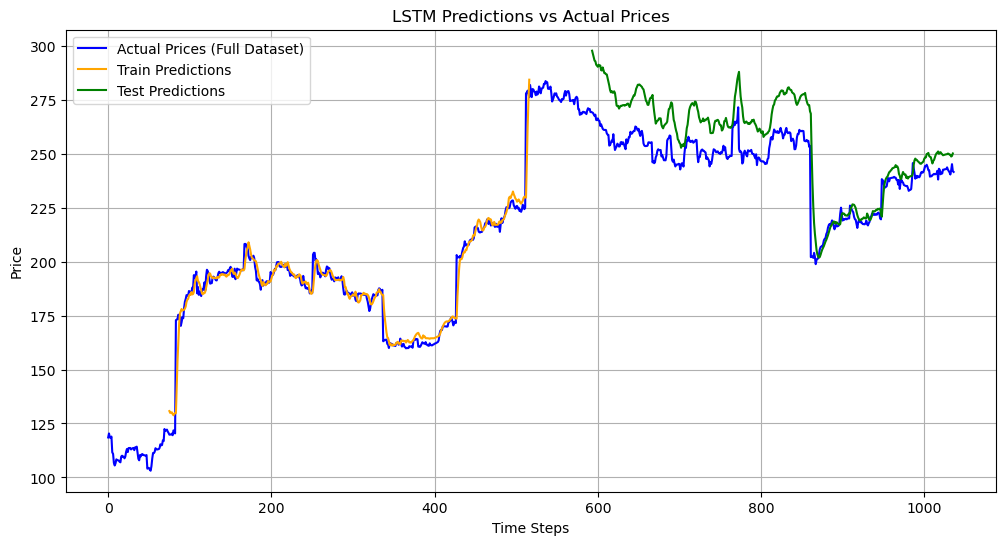

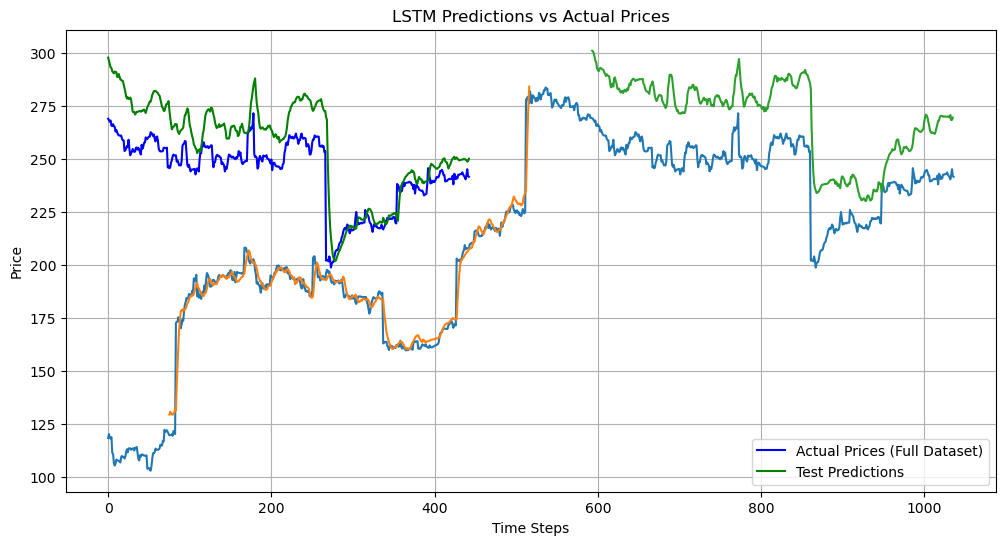

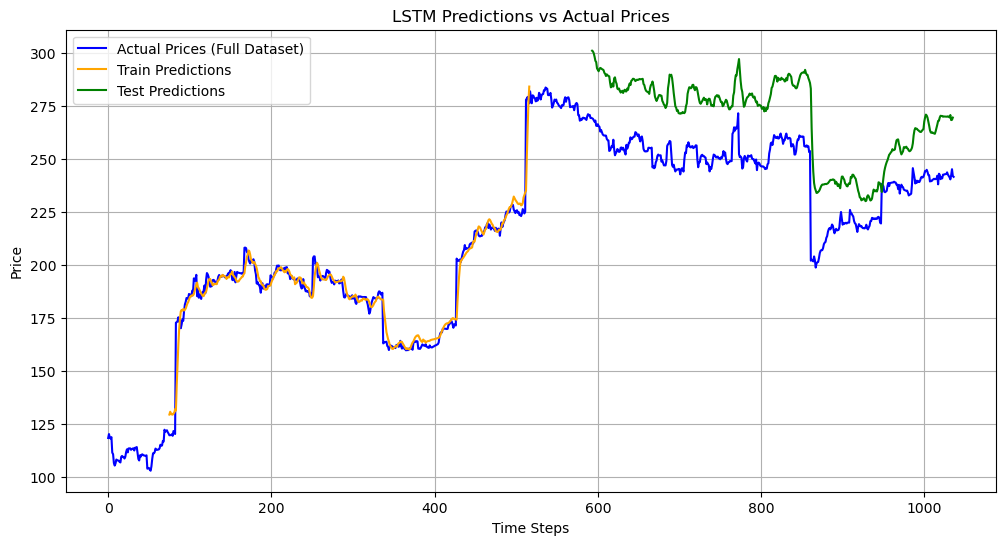

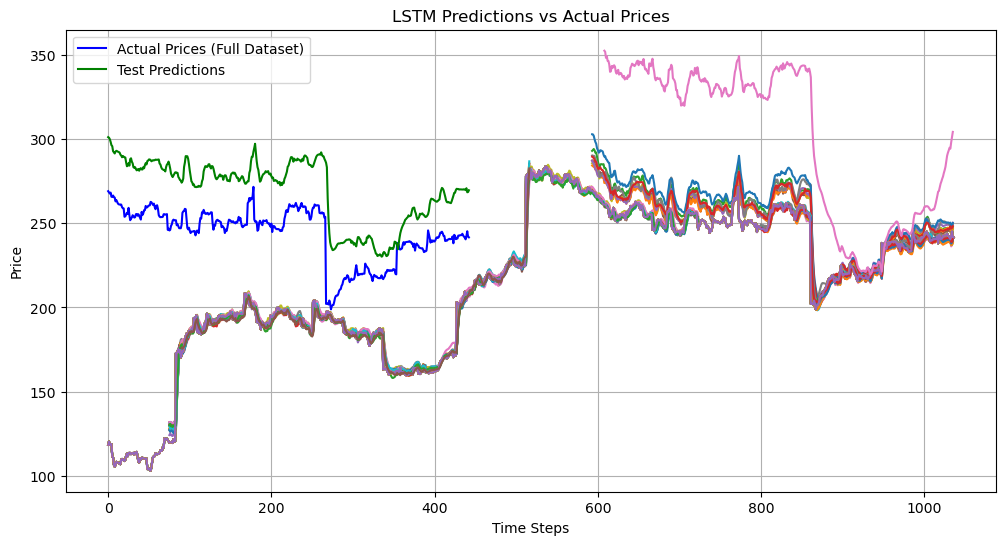

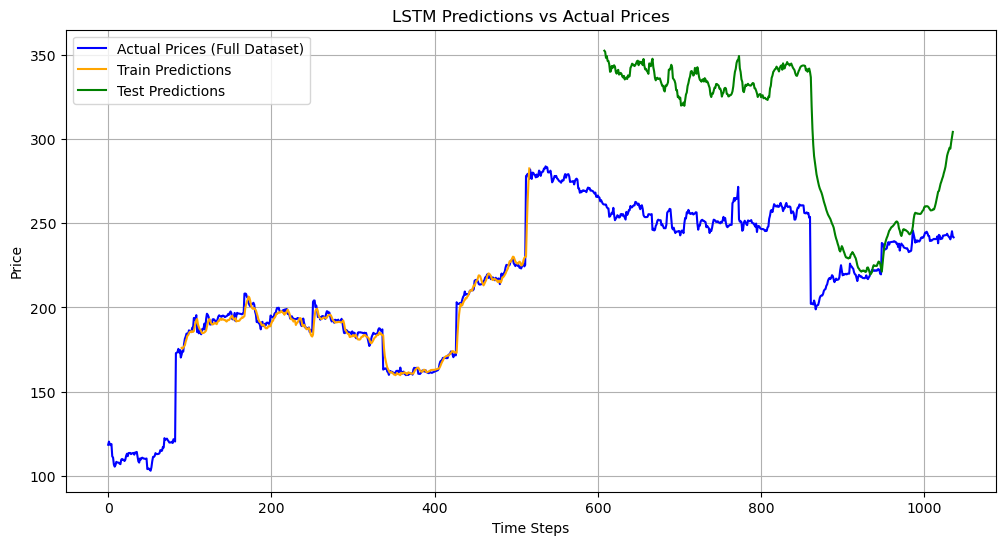

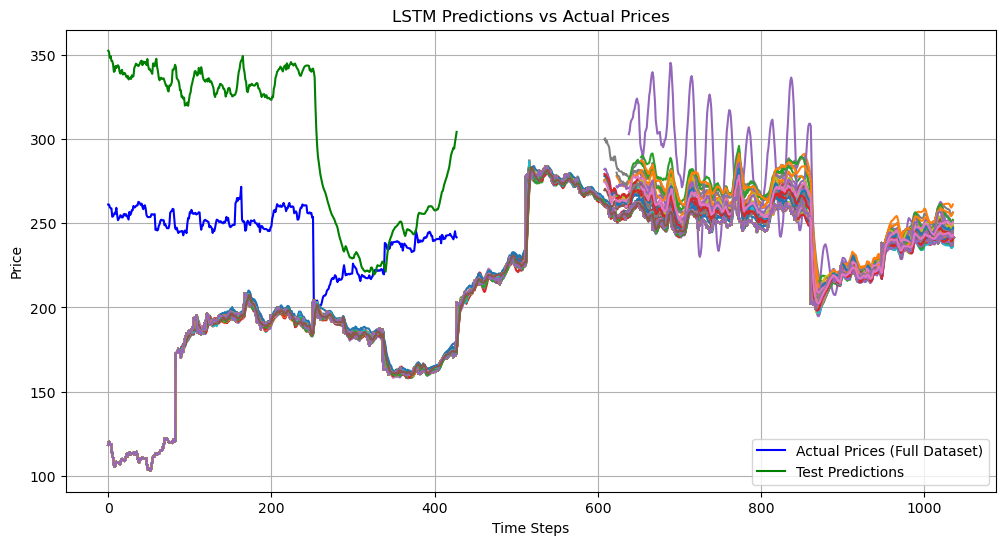

In [14]:
n_repeats = 10
lookbacks = np.arange(15, 150, 15)
train_sizes = [0.5, 0.7]
rows = []
best_mse = float("inf")
worst_mse = -float("inf")

for lookback, ts in itertools.product(lookbacks, train_sizes):
    for repeat in range(n_repeats):

        # fix random seed for reproducibility
        np.random.seed(5)
        # take close price column[5]
        #all_y = df["close"].values
        dataset = df[['close','avg_score_of_normalized_min', 'avg_score_of_normalized_max',
               'avg_score_of_normalized_avg']].values
        #dataset=all_y.reshape(-1, 1)
        target_col = 0 # target label is Close
        # normalize ALL features
        scaler = MinMaxScaler(feature_range=(0, 1))
        dataset = scaler.fit_transform(dataset)

        # split into train and test sets, 50% test data
        train_size = int(len(dataset) * ts)
        train, test = dataset[0:train_size, :], dataset[train_size:, :]

        # create supervised dataset
        look_back = lookback
        trainX, trainY = create_dataset(train, look_back, target_col)
        testX, testY = create_dataset(test, look_back, target_col)

        # reshape input to be [samples, time steps, features]
        n_features = dataset.shape[1]
        trainX = trainX.reshape(trainX.shape[0], look_back, n_features)
        testX = testX.reshape(testX.shape[0], look_back, n_features)
        # LSTM model
        model = Sequential()
        model.add(LSTM(25, input_shape=(look_back, n_features)))
        model.add(Dropout(0.1))
        model.add(Dense(1))
        model.compile(loss='mse', optimizer='adam')
        model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=0)

        # predictions
        trainPredict = model.predict(trainX)
        testPredict = model.predict(testX)

        # invert prediction scaling (only target)

        trainPredict = scaler.inverse_transform(
            np.repeat(trainPredict, n_features, axis=1)
        )[:,target_col]

        trainY_inv = scaler.inverse_transform(
            np.repeat(trainY.reshape(-1,1), n_features, axis=1)
        )[:,target_col]

        testPredict = scaler.inverse_transform(
            np.repeat(testPredict, n_features, axis=1)
        )[:,target_col]

        testY_inv = scaler.inverse_transform(
            np.repeat(testY.reshape(-1,1), n_features, axis=1)
        )[:,target_col]

        '''
        ## Cancelling normlarization
        trainPredict = np.repeat(trainPredict, n_features, axis=1)[:,target_col]

        trainY_inv = np.repeat(trainY.reshape(-1,1), n_features, axis=1)[:,target_col]

        testPredict = np.repeat(testPredict, n_features, axis=1)[:,target_col]

        testY_inv = np.repeat(testY.reshape(-1,1), n_features, axis=1)[:,target_col]
        '''


        # RMSE
        trainScore = math.sqrt(mean_squared_error(trainY_inv, trainPredict))
        testScore = math.sqrt(mean_squared_error(testY_inv, testPredict))
        print('Train Score: %.2f RMSE' % trainScore)
        print('Test Score: %.2f RMSE' % testScore)

        # prepare plotting arrays
        dataset_target = scaler.inverse_transform(dataset)[:, target_col]

        trainPredictPlot = np.empty_like(dataset_target)
        trainPredictPlot[:] = np.nan
        trainPredictPlot[look_back:len(trainPredict)+look_back] = trainPredict

        testPredictPlot = np.empty_like(dataset_target)
        testPredictPlot[:] = np.nan
        testPredictPlot[len(trainPredict)+(look_back*2)+1 : len(dataset_target)-1] = testPredict

        # plot
        plt.plot(dataset_target)
        plt.plot(trainPredictPlot)
        plt.plot(testPredictPlot)
        #plt.show()

        # export results
        testPrices = dataset_target[len(dataset_target)-len(testPredict):]
        #df_out = pd.DataFrame({"prediction": np.around(testPredict, 2),"test_price": np.around(testPrices, 2)})
        #df_out.to_csv("lstm_result_model3-financial and textual.csv", sep=';', index=None)

        # RMSE
        trainScore = math.sqrt(mean_squared_error(trainY_inv, trainPredict))
        testScore = math.sqrt(mean_squared_error(testY_inv, testPredict))
        #print('Train Score: %.2f RMSE' % trainScore)
        #print('Test Score: %.2f RMSE' % testScore)

        # plot actual prices and predictions
        if testScore < best_mse:
            best_mse = testScore
        
            plt.figure(figsize=(12,6))
            plt.plot(dataset_target, label="Actual Prices (Full Dataset)", color="blue")
            plt.plot(trainPredictPlot, label="Train Predictions", color="orange")
            plt.plot(testPredictPlot, label="Test Predictions", color="green")
            plt.legend()
            plt.title("LSTM Predictions vs Actual Prices")
            plt.xlabel("Time Steps")
            plt.ylabel("Price")
            plt.grid(True)
            plt.savefig(f"LSTM_Model2_Regression_best_mse_lb{lookback}_ts{ts}_repeat{repeat}.png")
            #plt.show()
            dataset_target.shape
            testPredictPlot=pd.Series(testPredictPlot).dropna().values
            test_size = testPredictPlot.shape[0]
            # RMSE
            trainScore = math.sqrt(mean_squared_error(trainY_inv, trainPredict))
            testScore = math.sqrt(mean_squared_error(testY_inv, testPredict))
            #print('Train Score: %.2f RMSE' % trainScore)
            #print('Test Score: %.2f RMSE' % testScore)

            # get actual test prices
            # plot actual prices and predictions
            plt.figure(figsize=(12,6))
            plt.plot(dataset_target[-test_size:], label="Actual Prices (Full Dataset)", color="blue")
            plt.plot(testPredictPlot, label="Test Predictions", color="green")
            plt.legend()
            plt.title("LSTM Predictions vs Actual Prices")
            plt.xlabel("Time Steps")
            plt.ylabel("Price")
            plt.grid(True)
            #plt.show()
        if testScore > worst_mse:
            worst_mse = testScore
            plt.figure(figsize=(12,6))
            plt.plot(dataset_target, label="Actual Prices (Full Dataset)", color="blue")
            plt.plot(trainPredictPlot, label="Train Predictions", color="orange")
            plt.plot(testPredictPlot, label="Test Predictions", color="green")
            plt.legend()
            plt.title("LSTM Predictions vs Actual Prices")
            plt.xlabel("Time Steps")
            plt.ylabel("Price")
            plt.grid(True)
            plt.savefig(f"LSTM_Model2_Regression_worst_mse_lb{lookback}_ts{ts}_repeat{repeat}.png")

            #plt.show()
            dataset_target.shape
            testPredictPlot=pd.Series(testPredictPlot).dropna().values
            test_size = testPredictPlot.shape[0]
            # RMSE
            trainScore = math.sqrt(mean_squared_error(trainY_inv, trainPredict))
            testScore = math.sqrt(mean_squared_error(testY_inv, testPredict))
            #print('Train Score: %.2f RMSE' % trainScore)
            #print('Test Score: %.2f RMSE' % testScore)

            # get actual test prices
            # plot actual prices and predictions
            plt.figure(figsize=(12,6))
            plt.plot(dataset_target[-test_size:], label="Actual Prices (Full Dataset)", color="blue")
            plt.plot(testPredictPlot, label="Test Predictions", color="green")
            plt.legend()
            plt.title("LSTM Predictions vs Actual Prices")
            plt.xlabel("Time Steps")
            plt.ylabel("Price")
            plt.grid(True)
            #plt.show()
            
            
            
            

        result = {"n_repeat": repeat,"lookback": look_back,"test_size": 1-ts,"train_rmse": trainScore, "test_rmse":testScore}
        rows.append(result)

df_results= pd.DataFrame(rows)


In [17]:

df_results.to_csv("LSTM_Model2_Regression__simulation.csv", index=False)